# 03 Falhas experimentais e escala da resposta

Um registro incorreto, uma coleta com deriva e uma escala inadequada podem mudar a interpretação dos efeitos. Vamos acompanhar essas três situações em um fatorial completo $2^2r$.

Todos os dados são artificiais e gerados neste notebook. Cada entrada corresponde a uma sessão planejada como unidade experimental. As versões com falha são identificadas antes da análise. O exemplo de transcrição mantém as mesmas sessões e corrige somente o registro cuja origem é conhecida. O exemplo de deriva exige uma nova campanha.

Os coeficientes $q_A$, $q_B$ e $q_{AB}$ seguem a convenção de Jain. O efeito fatorial na convenção de diferença média entre sinais alto e baixo é $2q$. Uma diferença simples de A, mantendo $B=b$, é $2(q_A+bq_{AB})$.


In [1]:
from pathlib import Path
from itertools import combinations, product
import base64
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

NOME_NOTEBOOK = '03_falhas_experimentais_22r'
CONFIANCA = CONFIDENCE_LEVEL = 0.90
ALPHA = 1-CONFIANCA
BASE = Path.cwd()
if BASE.name == 'notebooks':
    BASE = BASE.parent
FIGURAS = BASE/'figuras'/NOME_NOTEBOOK
TABELAS = BASE/'tabelas'/NOME_NOTEBOOK
FIGURAS.mkdir(parents=True,exist_ok=True)
TABELAS.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({
    'font.family':'serif','font.serif':['STIXGeneral','DejaVu Serif'],
    'mathtext.fontset':'stix','font.size':11,'axes.labelsize':11,
    'xtick.labelsize':9,'ytick.labelsize':9,'legend.fontsize':9,
    'figure.dpi':130,'figure.facecolor':'white','axes.facecolor':'white',
    'axes.spines.top':False,'axes.spines.right':False,'axes.grid':False,
    'axes.linewidth':.8,'lines.linewidth':1.4,'lines.markersize':4.5,
    'pdf.fonttype':42,'ps.fonttype':42,'savefig.facecolor':'white'})
AZUL='#24577A'
LARANJA='#B76532'
VERDE='#44735B'
CINZA='#707070'
CORES=[AZUL,LARANJA,VERDE,CINZA]
pd.set_option('display.max_columns',14)
pd.set_option('display.float_format',lambda x:f'{x:.5g}')

def salvar_figura(fig,nome):
    if any(ax.get_title() or ax.get_title(loc='left') or ax.get_title(loc='right') for ax in fig.axes):
        raise ValueError('A identificação pertence à legenda externa da figura')
    if getattr(fig,'_suptitle',None) is not None:
        raise ValueError('A identificação pertence ao texto')
    w,h=fig.get_size_inches()
    if w>10 or h>10 or w<3 or h<2:
        raise ValueError('Dimensões físicas inadequadas')
    pdf=FIGURAS/f'{nome}.pdf'
    png=FIGURAS/f'{nome}.png'
    fig.savefig(pdf,format='pdf',dpi=600)
    fig.savefig(png,format='png',dpi=180)
    largura=1000 if len(fig.axes)>1 else 820
    display({'image/png':base64.b64encode(png.read_bytes()).decode('ascii')},raw=True,
        metadata={'image/png':{'width':largura,'height':round(largura*h/w)},
                  'fatorial_pdf':str(pdf.relative_to(BASE)),
                  'largura_polegadas':float(w),'altura_polegadas':float(h)})
    plt.close(fig)

def salvar_tabela(tabela,nome,indice=False,colunas_p=None):
    tabela.to_csv(TABELAS/f'{nome}.csv',index=indice)
    copia=tabela.copy()
    if colunas_p:
        for col in colunas_p:
            copia[col]=copia[col].map(lambda p:'' if pd.isna(p) else formatar_p(p))
    display(copia)

def formatar_p(p):
    return '< 1e-300' if p<=0 else f'{p:.4g}'

def decisao_teste(nome,p,contra,sem_evidencia):
    if not np.isfinite(p):
        display(Markdown(f'**{nome}**\n\nO valor-p não está definido para estes dados. A decisão depende do gráfico e das condições do diagnóstico.'))
        return
    if p<=ALPHA:
        texto=f'É significativo porque o valor-p {formatar_p(p)} é menor ou igual a {ALPHA:.2f}. {contra}'
    else:
        texto=f'Não é significativo porque o valor-p {formatar_p(p)} é maior que {ALPHA:.2f}. {sem_evidencia}'
    display(Markdown(f'**{nome}**\n\n{texto}'))

def matriz_sinais(k):
    if not isinstance(k,(int,np.integer)) or not 1<=k<=8:
        raise ValueError('Use entre um e oito fatores no fatorial completo')
    g=2**k
    niveis=2*((np.arange(g)[:,None]>>np.arange(k))&1)-1
    letras=[chr(65+i) for i in range(k)]
    termos=[]
    colunas=[]
    for mascara in range(g):
        ids=[j for j in range(k) if mascara&(1<<j)]
        termos.append(''.join(letras[j] for j in ids) if ids else '0')
        colunas.append(np.prod(niveis[:,ids],axis=1) if ids else np.ones(g))
    return niveis,np.column_stack(colunas),termos

def ajustar(response):
    response=np.asarray(response,dtype=float)
    if response.ndim!=2 or response.shape[0]<2:
        raise ValueError('Use uma matriz com combinações nas linhas e replicações nas colunas')
    g,r=response.shape
    k=int(np.log2(g))
    if 2**k!=g or r<2 or not np.isfinite(response).all():
        raise ValueError('O desenho completo exige 2**k combinações e pelo menos duas replicações finitas')
    niveis,Xc,termos=matriz_sinais(k)
    N=response.size
    nu=g*(r-1)
    medias=response.mean(axis=1)
    q=Xc.T@medias/g
    X=np.repeat(Xc,r,axis=0)
    y=response.ravel()
    ajustados=X@q
    residuos=y-ajustados
    SSE=float(residuos@residuos)
    SST=float(np.sum((y-y.mean())**2))
    MSE=SSE/nu
    if MSE<=np.finfo(float).eps*max(1,float(np.mean(y*y))):
        raise ValueError('O erro puro é nulo ou numericamente desprezível')
    SS=N*q[1:]**2
    se=np.sqrt(MSE)
    sq=se/np.sqrt(N)
    t=q[1:]/sq
    pval=2*stats.t.sf(np.abs(t),nu)
    crit=stats.t.ppf(1-ALPHA/2,nu)
    efeitos=pd.DataFrame({'Termo':termos[1:],'q':q[1:],'EP de q':sq,
        'IC inferior':q[1:]-crit*sq,'IC superior':q[1:]+crit*sq,
        'Efeito 2q':2*q[1:],'t':t,'Valor-p':pval,
        'Significativo':np.where(pval<=ALPHA,'Sim','Não')})
    anova=pd.DataFrame({'Fonte':termos[1:]+['Erro','Total'],
        'SS':np.r_[SS,SSE,SST],'gl':np.r_[np.ones(g-1,dtype=int),nu,N-1],
        'MS':np.r_[SS,MSE,np.nan],'F':np.r_[SS/MSE,np.nan,np.nan],
        'Valor-p':np.r_[pval,np.nan,np.nan]})
    F_global=float(np.sum(SS)/(g-1)/MSE)
    p_global=float(stats.f.sf(F_global,g-1,nu))
    assert np.isclose(SST,SS.sum()+SSE)
    assert np.allclose(Xc.T@Xc,g*np.eye(g))
    assert np.allclose(SS/MSE,t*t)
    return dict(response=response,k=k,g=g,r=r,N=N,nu=nu,Xc=Xc,X=X,niveis=niveis,
        termos=termos,q=q,y=y,medias=medias,ajustados=ajustados,residuos=residuos,
        SSE=SSE,SST=SST,SS=SS,MSE=MSE,se=se,sq=sq,anova=anova,efeitos=efeitos,
        F_global=F_global,p_global=p_global)

def modelo_escrito(res,nomes=None,resposta='y'):
    partes=[f'{res["q"][0]:.4g}']
    for termo,valor in zip(res['termos'][1:],res['q'][1:]):
        produto=''.join('x_{'+letra+'}' for letra in termo)
        partes.append((' + ' if valor>=0 else ' - ')+f'{abs(valor):.4g}'+produto)
    display(Markdown('$$\\widehat{'+resposta+'}='+''.join(partes)+'.$$'))

def mostrar_resultados(res):
    salvar_tabela(res['efeitos'],'efeitos_ic_testes',colunas_p=['Valor-p'])
    for termo,p in zip(res['termos'][1:],res['efeitos']['Valor-p']):
        decisao_teste(f'Efeito q{termo}',p,
            f'Há evidência de que q{termo} difere de zero nas condições do modelo.',
            f'Não há evidência suficiente de que q{termo} difere de zero. Isso não demonstra ausência de efeito.')

def mostrar_anova(res):
    salvar_tabela(res['anova'],'anova',colunas_p=['Valor-p'])
    tabela=pd.DataFrame([{'F global':res['F_global'],'gl numerador':res['g']-1,
        'gl denominador':res['nu'],'Valor-p':res['p_global']}])
    salvar_tabela(tabela,'F_global',colunas_p=['Valor-p'])
    decisao_teste('Teste F global',res['p_global'],
        'Há evidência de que pelo menos um termo do modelo difere de zero.',
        'Não há evidência suficiente de diferença entre as médias das combinações.')

def graficos_efeitos(res,prefixo):
    fig,ax=plt.subplots(figsize=(5,3),layout='constrained')
    ids=np.arange(res['g']-1)
    margem=stats.t.ppf(1-ALPHA/2,res['nu'])*res['sq']
    ax.errorbar(res['q'][1:],ids,xerr=margem,fmt='o',capsize=3,color=AZUL)
    ax.axvline(0,color=CINZA,lw=.8)
    ax.set_yticks(ids,['q'+t for t in res['termos'][1:]])
    ax.set_xlabel('Coeficiente q e IC de 90% ('+res.get('unidade','u.r.')+')')
    ax.set_ylabel('Termo')
    salvar_figura(fig,prefixo+'_efeitos')

def grafico_variacao(res,prefixo):
    nomes=res['termos'][1:]+['Erro']
    percent=100*np.r_[res['SS'],res['SSE']]/res['SST']
    tabela=pd.DataFrame({'Fonte':nomes,'SS':np.r_[res['SS'],res['SSE']],
                        'Variação alocada (%)':percent})
    salvar_tabela(tabela,prefixo+'_variacao')
    fig,ax=plt.subplots(figsize=(5,3),layout='constrained')
    ordem=np.argsort(percent)
    ax.barh(np.asarray(nomes)[ordem],percent[ordem],color=[CINZA if nomes[i]=='Erro' else AZUL for i in ordem])
    ax.set_xlabel('Variação total alocada (%)')
    ax.set_ylabel('Fonte')
    salvar_figura(fig,prefixo+'_variacao')

def graficos_niveis(res,nomes,niveis_reais,prefixo,com_ic=True):
    k=res['k']
    cols=min(2,k)
    rows=int(np.ceil(k/cols))
    tamanho=(5,3) if rows==1 else (5,5)
    fig,axes=plt.subplots(rows,cols,figsize=tamanho,squeeze=False,layout='constrained')
    ep=res['se']/np.sqrt(res['N']/2)
    margem=stats.t.ppf(1-ALPHA/2,res['nu'])*ep
    for j,ax in enumerate(axes.ravel()):
        if j>=k:
            ax.set_visible(False)
            continue
        vals=[res['medias'][res['niveis'][:,j]==a].mean() for a in [-1,1]]
        if com_ic:ax.errorbar([0,1],vals,yerr=margem,fmt='o-',capsize=3,color=AZUL)
        else:ax.plot([0,1],vals,'o-',color=AZUL)
        ax.set_xticks([0,1],niveis_reais[j])
        ax.set_xlabel(nomes[j])
        ax.set_ylabel('Média ('+res.get('unidade','u.r.')+')'+(' e IC de 90%' if com_ic else ''))
        ax.text(.01,1.025,f'({chr(97+j)})',transform=ax.transAxes,ha='left',va='bottom')
        ax.margins(x=.15)
    salvar_figura(fig,prefixo+'_niveis')

def graficos_interacoes(res,nomes,niveis_reais,prefixo,com_ic=True):
    k=res['k']
    paineis=[]
    if k==1:return
    for a,b in combinations(range(k),2):
        outros=[j for j in range(k) if j not in [a,b]]
        for condicao in product([-1,1],repeat=len(outros)):
            paineis.append((a,b,outros,condicao))
    if k==2:paineis.append((1,0,[],()))
    margem=stats.t.ppf(1-ALPHA/2,res['nu'])*res['se']/np.sqrt(res['r'])
    for inicio in range(0,len(paineis),6):
        bloco=paineis[inicio:inicio+6]
        cols=2 if len(bloco)<=4 else 3
        rows=int(np.ceil(len(bloco)/cols))
        tamanho=(5,3) if rows==1 else ((5,5) if cols==2 else (7,5))
        fig,axes=plt.subplots(rows,cols,figsize=tamanho,squeeze=False,layout='constrained')
        mapa=[]
        for t,ax in enumerate(axes.ravel()):
            if t>=len(bloco):
                ax.set_visible(False)
                continue
            a,b,outros,condicao=bloco[t]
            cond=np.ones(res['g'],dtype=bool)
            for j,v in zip(outros,condicao):cond&=res['niveis'][:,j]==v
            for nivel,cor in [(-1,AZUL),(1,LARANJA)]:
                ys=[res['medias'][cond&(res['niveis'][:,a]==x)&(res['niveis'][:,b]==nivel)].mean() for x in [-1,1]]
                rotulo=niveis_reais[b][0 if nivel==-1 else 1]
                if com_ic:ax.errorbar([0,1],ys,yerr=margem,fmt='o-',capsize=2.5,label=rotulo,color=cor)
                else:ax.plot([0,1],ys,'o-',label=rotulo,color=cor)
            letra=chr(97+t)
            ax.text(.01,1.025,f'({letra})',transform=ax.transAxes,ha='left',va='bottom')
            ax.set_xticks([0,1],niveis_reais[a])
            ax.set_xlabel(nomes[a])
            ax.set_ylabel('Média ('+res.get('unidade','u.r.')+')')
            ax.margins(x=.15,y=.16)
            ax.legend(frameon=False,title=nomes[b],fontsize=8,title_fontsize=9)
            fixos=', '.join(f'{nomes[j]} em {niveis_reais[j][0 if v==-1 else 1]}' for j,v in zip(outros,condicao))
            mapa.append(f'({letra}) {nomes[a]} e {nomes[b]}'+(', '+fixos if fixos else ''))
        display(Markdown('Painéis do gráfico. '+'. '.join(mapa)+'.'))
        salvar_figura(fig,prefixo+f'_interacoes_{inicio//6+1}')

def grid_residuos(res,ordem,prefixo):
    ordem=np.asarray(ordem,dtype=int)
    if not np.array_equal(np.sort(ordem),np.arange(res['N'])):
        raise ValueError('A ordem deve conter cada índice de observação uma vez')
    fig,axes=plt.subplots(2,2,figsize=(5,5),layout='constrained')
    ax=axes[0,0]
    ax.scatter(res['ajustados'],res['residuos'],s=17,color=AZUL)
    ax.axhline(0,color=CINZA,lw=.7)
    ax.set_xlabel('Resposta ajustada ('+res.get('unidade','u.r.')+')')
    ax.set_ylabel('Resíduo ('+res.get('unidade','u.r.')+')')
    ax=axes[0,1]
    for i in range(res['g']):
        ax.scatter(i+1+np.linspace(-.13,.13,res['r']),res['residuos'].reshape(res['g'],res['r'])[i],s=17,color=AZUL)
    ax.axhline(0,color=CINZA,lw=.7)
    ax.set_xlabel('Combinação')
    ax.set_ylabel('Resíduo ('+res.get('unidade','u.r.')+')')
    ax.set_xticks(np.arange(1,res['g']+1))
    ax=axes[1,0]
    quantis,observados=stats.probplot(res['residuos']/(res['se']*np.sqrt(1-1/res['r'])),dist='norm',fit=False)
    ax.scatter(quantis,observados,s=17,color=AZUL)
    ax.plot([min(quantis),max(quantis)],[min(quantis),max(quantis)],color=CINZA,lw=.8)
    ax.set_xlabel('Quantil normal teórico')
    ax.set_ylabel('Resíduo em\nescala comparável')
    ax=axes[1,1]
    ax.plot(np.arange(1,res['N']+1),res['residuos'][ordem],'o-',markersize=3,lw=.8,color=AZUL)
    ax.axhline(0,color=CINZA,lw=.7)
    ax.set_xlabel('Ordem de execução')
    ax.set_ylabel('Resíduo ('+res.get('unidade','u.r.')+')')
    for i,ax in enumerate(axes.ravel()):
        ax.text(.01,1.025,f'({chr(97+i)})',transform=ax.transAxes,ha='left',va='bottom')
    salvar_figura(fig,prefixo+'_residuos')

def _estatistica_ks(amostras):
    amostras=np.atleast_2d(amostras)
    n=amostras.shape[1]
    z=(amostras-amostras.mean(axis=1,keepdims=True))/amostras.std(axis=1,ddof=1,keepdims=True)
    F=stats.norm.cdf(np.sort(z,axis=1))
    return np.maximum(np.max(np.arange(1,n+1)/n-F,axis=1),
                      np.max(F-np.arange(n)/n,axis=1))

def diagnosticos(res,ordem,prefixo):
    ordem=np.asarray(ordem,dtype=int)
    if not np.array_equal(np.sort(ordem),np.arange(res['N'])):
        raise ValueError('A ordem deve ser uma permutação dos índices das observações')
    if res['r']==2:
        W_variancia,p_variancia=np.nan,np.nan
    else:
        W_variancia,p_variancia=stats.levene(*res['response'],center='median')
    e=res['residuos']
    W=float(stats.shapiro(e).statistic)
    D=float(_estatistica_ks(e)[0])
    DW=float(np.sum(np.diff(e[ordem])**2)/np.sum(e*e))
    B=4999
    rng=np.random.default_rng(180042)
    erros=rng.normal(size=(B,res['g'],res['r']))
    simulados=(erros-erros.mean(axis=2,keepdims=True)).reshape(B,res['N'])
    Ws=stats.shapiro(simulados,axis=1).statistic
    Ds=_estatistica_ks(simulados)
    DWs=np.sum(np.diff(simulados[:,ordem],axis=1)**2,axis=1)/np.sum(simulados*simulados,axis=1)
    p_W=(1+np.count_nonzero(Ws<=W))/(B+1)
    p_D=(1+np.count_nonzero(Ds>=D))/(B+1)
    p_DW=min(1,2*min((1+np.count_nonzero(DWs<=DW))/(B+1),
                     (1+np.count_nonzero(DWs>=DW))/(B+1)))
    tabela=pd.DataFrame({'Diagnóstico':['Brown e Forsythe','Shapiro e Wilk','Kolmogorov e Smirnov','Durbin e Watson'],
        'Estatística':[W_variancia,W,D,DW],
        'Valor-p':[p_variancia,p_W,p_D,p_DW],
        'Referência':['F aproximada','Normal no mesmo desenho','Normal no mesmo desenho','Normal independente no mesmo desenho']})
    salvar_tabela(tabela,prefixo+'_diagnosticos',colunas_p=['Valor-p'])
    if res['r']==2:
        display(Markdown('Com duas replicações por combinação, os dois desvios absolutos em relação à mediana são iguais. O teste de Brown e Forsythe fica degenerado. A comparação de dispersões deve usar os gráficos e exige mais replicações para esse teste.'))
    decisao_teste('Homocedasticidade',p_variancia,
        'Há evidência contra a igualdade das variâncias.',
        'Não há evidência suficiente contra a igualdade das variâncias.')
    for nome,p in [('Shapiro e Wilk',p_W),('Kolmogorov e Smirnov',p_D)]:
        decisao_teste(nome,p,'Há evidência contra a normalidade dos erros sob a referência adotada.',
            'Não há evidência suficiente contra a normalidade sob a referência adotada.')
    decisao_teste('Durbin e Watson',p_DW,
        'Há evidência de dependência serial na comparação com a referência independente.',
        'Não há evidência suficiente de dependência serial nessa comparação. O protocolo continua necessário.')
    return tabela

def grid_padroes(prefixo):
    rng=np.random.default_rng(180043)
    n=80
    x=np.linspace(-1,1,n)
    iid=rng.normal(0,1,n)
    pos=np.zeros(n)
    neg=np.zeros(n)
    for i in range(1,n):
        pos[i]=.83*pos[i-1]+rng.normal(0,.6)
        neg[i]=-.83*neg[i-1]+rng.normal(0,.6)
    padroes=[iid,pos,neg,2*np.sin(np.linspace(0,5*np.pi,n))+rng.normal(0,.3,n),
        rng.normal(0,np.linspace(.2,2,n)),3*(x*x-x.dot(x)/n)+rng.normal(0,.3,n)]
    fig,axes=plt.subplots(2,3,figsize=(7,5),layout='constrained')
    for i,(ax,e) in enumerate(zip(axes.ravel(),padroes)):
        eixo=np.arange(1,n+1) if i<4 else x
        if i<4:ax.plot(eixo,e,'o-',markersize=2,lw=.7,color=AZUL)
        else:ax.scatter(eixo,e,s=11,color=AZUL)
        ax.axhline(0,color=CINZA,lw=.7)
        ax.set_xlabel('Ordem' if i<4 else 'Valor ajustado')
        ax.set_ylabel('Resíduo ilustrativo')
        ax.text(.01,1.025,f'({chr(97+i)})',transform=ax.transAxes,va='bottom')
    salvar_figura(fig,prefixo+'_padroes')

def graficos_comparacao(resultados,rotulos,prefixo):
    fig,axes=plt.subplots(1,len(resultados),figsize=(5,3) if len(resultados)<=2 else (7,3),
                          squeeze=False,layout='constrained')
    for i,(res,rotulo) in enumerate(zip(resultados,rotulos)):
        ax=axes[0,i]
        margem=stats.t.ppf(1-ALPHA/2,res['nu'])*res['sq']
        ax.errorbar(res['q'][1:],np.arange(res['g']-1),xerr=margem,fmt='o',capsize=3,color=CORES[i%4])
        ax.axvline(0,color=CINZA,lw=.7)
        ax.set_yticks(np.arange(res['g']-1),['q'+t for t in res['termos'][1:]])
        ax.set_xlabel('q e IC de 90% ('+res.get('unidade','u.r.')+')')
        ax.set_ylabel(rotulo)
    salvar_figura(fig,prefixo+'_comparacao')

from pathlib import Path
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


def _dados_combinacoes(res, nomes, niveis_reais):
    response = np.asarray(res['response'], dtype=float)
    if response.ndim != 2 or response.shape[0] < 2 or response.shape[1] < 2 or not np.isfinite(response).all():
        raise ValueError('Use respostas finitas com ao menos duas replicações por combinação')
    g, r = response.shape
    k = int(np.log2(g))
    if 2**k != g or len(nomes) != k or len(niveis_reais) != k:
        raise ValueError('Os fatores e os níveis devem corresponder ao fatorial completo')
    if len(set(nomes)) != k or any(len(par) != 2 for par in niveis_reais):
        raise ValueError('Use nomes distintos e dois níveis reais por fator')
    niveis = np.asarray(res['niveis'], dtype=int)
    if niveis.shape != (g, k) or not np.isin(niveis, [-1, 1]).all():
        raise ValueError('A matriz de níveis deve acompanhar as linhas da resposta')
    if np.unique(niveis, axis=0).shape[0] != g:
        raise ValueError('As combinações devem aparecer uma vez na matriz de níveis')
    medias = response.mean(axis=1)
    nu = g * (r - 1)
    mse = float(np.sum((response - medias[:, None])**2) / nu)
    if not np.isfinite(mse) or mse < 0:
        raise ValueError('O erro puro precisa produzir uma variância finita')
    if 'MSE' in res and not np.isclose(float(res['MSE']), mse, rtol=1e-9, atol=1e-12):
        raise ValueError('MSE deve ser o erro puro comum do modelo completo')
    ep = np.sqrt(mse / r)
    quantil = float(stats.t.ppf(0.95, nu))
    margem = quantil * ep
    experimentos = [f'Exp{i + 1}' for i in range(g)]
    codigos = [''.join(chr(65 + j) + ('+' if nivel == 1 else '-')
                       for j, nivel in enumerate(linha)) for linha in niveis]
    desenho = pd.DataFrame({'Experimento': experimentos, 'Combinação': codigos})
    for j, nome in enumerate(nomes):
        desenho[nome] = [str(niveis_reais[j][0 if v == -1 else 1]) for v in niveis[:, j]]
    resumo = desenho.copy()
    resumo['Replicações'] = r
    resumo['Média'] = medias
    resumo['MSE comum'] = mse
    resumo['Graus de liberdade'] = nu
    resumo['EP da média'] = ep
    resumo['Quantil t de 90%'] = quantil
    resumo['IC90 inferior'] = medias - margem
    resumo['IC90 superior'] = medias + margem
    rng = np.random.default_rng(180501)
    jitter = np.vstack([rng.permutation(np.linspace(-0.12, 0.12, r)) for _ in range(g)])
    pontos = pd.DataFrame({
        'Experimento': np.repeat(experimentos, r),
        'Combinação': np.repeat(codigos, r),
        'Replicação': np.tile(np.arange(1, r + 1), g),
        'Resposta': response.ravel(),
        'Média do tratamento': np.repeat(medias, r),
        'Deslocamento horizontal': jitter.ravel(),
        'Posição horizontal': (np.arange(g)[:, None] + jitter).ravel()
    })
    return dict(response=response, g=g, r=r, k=k, niveis=niveis, medias=medias,
                nu=nu, mse=mse, ep=ep, margem=margem, jitter=jitter,
                experimentos=experimentos, codigos=codigos, desenho=desenho,
                resumo=resumo, pontos=pontos, unidade=str(res.get('unidade', 'u.r.')))


def _tabela_niveis(ax, dados, nomes):
    ax.set_axis_off()
    linhas = [[textwrap.fill(str(v), width=10, break_long_words=False)
               for v in dados['desenho'][nome]] for nome in nomes]
    tabela = ax.table(cellText=linhas, rowLabels=nomes,
                      colLabels=dados['experimentos'], cellLoc='center',
                      rowLoc='left', loc='center', bbox=[0, 0, 1, 1])
    tabela.auto_set_font_size(False)
    tabela.set_fontsize(8 if dados['g'] <= 4 else 7)
    for (linha, coluna), celula in tabela.get_celld().items():
        celula.set_linewidth(0.45)
        celula.set_edgecolor('#A0A0A0')
        celula.PAD = 0.025
        if linha == 0:
            celula.set_facecolor('#F0F0F0')
        if coluna == -1:
            celula.set_text_props(weight='bold')
    return tabela


def _eixos_combinacoes(dados, nomes, n_paineis, com_tabela, compartilhar_y):
    if n_paineis not in (1, 2):
        raise ValueError('Use um cenário ou dois cenários lado a lado')
    if n_paineis == 1:
        tamanho = (5, 4) if com_tabela else (5, 3)
        if dados['g'] > 8:
            tamanho = (9, 4.5) if com_tabela else (9, 3)
    else:
        tamanho = (7, 4) if com_tabela else (7, 3.5)
    fig = plt.figure(figsize=tamanho, layout='constrained')
    if com_tabela:
        grade = fig.add_gridspec(2, n_paineis, height_ratios=[3.3, 1.1])
    else:
        grade = fig.add_gridspec(1, n_paineis)
    eixos = []
    for i in range(n_paineis):
        eixo = fig.add_subplot(grade[0, i], sharey=eixos[0] if compartilhar_y and i else None)
        eixo.tick_params(axis='both', labelsize=9)
        eixo.tick_params(axis='y', labelleft=True)
        eixos.append(eixo)
    if com_tabela:
        _tabela_niveis(fig.add_subplot(grade[1, :]), dados, nomes)
    return fig, eixos


def _painel_pontos(ax, dados, rotulos_x):
    cores = globals().get('CORES', ['#24577A', '#B76532', '#44735B', '#707070'])
    for i, valores in enumerate(dados['response']):
        ax.scatter(i + dados['jitter'][i], valores, s=24,
                   color=cores[i % len(cores)], alpha=0.80, zorder=3)
        ax.hlines(dados['medias'][i], i - 0.21, i + 0.21, color='black',
                  linewidth=1.8, zorder=5, label='Média do tratamento' if i == 0 else None)
    ax.set_xticks(np.arange(dados['g']), rotulos_x)
    ax.set_xlim(-0.55, dados['g'] - 0.45)
    ax.set_xlabel('Combinação dos fatores')
    ax.set_ylabel(f'Resposta ({dados["unidade"]})')
    ax.margins(y=0.12)
    ax.legend(frameon=False, fontsize=8, loc='best')


def _painel_barras(ax, dados, rotulos_x):
    x = np.arange(dados['g'])
    ax.bar(x, dados['medias'], width=0.62, color='#24577A', alpha=0.84, zorder=2)
    ax.errorbar(x, dados['medias'], yerr=dados['margem'], fmt='none',
                ecolor='black', elinewidth=1.1, capsize=3.0, capthick=1.1, zorder=4)
    for i, media in enumerate(dados['medias']):
        ax.annotate(f'{media:.3g}', xy=(i, media + dados['margem']),
                    xytext=(0, 4), textcoords='offset points', ha='center',
                    va='bottom', fontsize=8, clip_on=False)
    ax.set_xticks(x, rotulos_x)
    ax.set_xlim(-0.55, dados['g'] - 0.45)
    ax.set_xlabel('Combinação dos fatores')
    ax.set_ylabel(f'Média e IC de 90% ({dados["unidade"]})')
    ax.margins(y=0.20)


def _gravar_dados_combinacoes(dados, prefixo, rotulos):
    grupos_pontos, grupos_medias = [], []
    for painel, rotulo in zip(dados, rotulos):
        pontos = painel['pontos'].copy()
        medias = painel['resumo'].copy()
        if len(dados) > 1:
            pontos.insert(0, 'Cenário', rotulo)
            medias.insert(0, 'Cenário', rotulo)
        grupos_pontos.append(pontos)
        grupos_medias.append(medias)
    tabelas = {'observacoes': pd.concat(grupos_pontos, ignore_index=True),
               'medias_ic90': pd.concat(grupos_medias, ignore_index=True),
               'niveis': dados[0]['desenho'].copy()}
    if 'TABELAS' in globals():
        pasta = Path(globals()['TABELAS'])
        pasta.mkdir(parents=True, exist_ok=True)
        for sufixo, tabela in tabelas.items():
            tabela.to_csv(pasta / f'{prefixo}_{sufixo}.csv', index=False)
    return tabelas


def _gerar_graficos_combinacoes(resultados, rotulos, nomes, niveis_reais, prefixo,
                               compartilhar_y, com_tabela):
    dados = [_dados_combinacoes(res, nomes, niveis_reais) for res in resultados]
    if not dados or len(dados) != len(rotulos):
        raise ValueError('Informe um rótulo para cada cenário')
    if any(not painel['desenho'].equals(dados[0]['desenho']) for painel in dados[1:]):
        raise ValueError('Os painéis precisam representar as mesmas combinações')
    if compartilhar_y and len({painel['unidade'] for painel in dados}) > 1:
        raise ValueError('Escalas compartilhadas exigem a mesma unidade da resposta')
    com_tabela = dados[0]['k'] >= 3 if com_tabela is None else bool(com_tabela)
    rotulos_x = dados[0]['experimentos'] if com_tabela else dados[0]['codigos']
    if len(dados) == 2:
        fig = plt.figure(figsize=(7, 6) if com_tabela else (7, 5), layout='constrained')
        grade = fig.add_gridspec(3, 2, height_ratios=[1, 1, 0.48]) if com_tabela else fig.add_gridspec(2, 2)
        for linha, desenhar in enumerate([_painel_pontos, _painel_barras]):
            primeiro = None
            for coluna, painel in enumerate(dados):
                ax = fig.add_subplot(grade[linha, coluna],
                                     sharey=primeiro if compartilhar_y and coluna else None)
                if coluna == 0:
                    primeiro = ax
                desenhar(ax, painel, rotulos_x)
                ax.tick_params(axis='both', labelsize=9)
                ax.tick_params(axis='y', labelleft=True)
                letra = chr(97 + 2 * linha + coluna)
                ax.text(0.01, 1.045, f'({letra})', transform=ax.transAxes,
                        ha='left', va='bottom', fontsize=10)
        if com_tabela:
            _tabela_niveis(fig.add_subplot(grade[2, :]), dados[0], nomes)
        descricoes = [f'Pontos de {rotulos[0]}', f'Pontos de {rotulos[1]}',
                      f'Média e IC de {rotulos[0]}', f'Média e IC de {rotulos[1]}']
        mapa = '. '.join(f'({chr(97 + i)}) {rotulo}' for i, rotulo in enumerate(descricoes))
        display(Markdown('Painéis do gráfico. ' + mapa + '.'))
        salvar_figura(fig, f'{prefixo}_pontos_medias_ic90')
        return _gravar_dados_combinacoes(dados, prefixo, rotulos)
    for tipo, desenhar in [('pontos', _painel_pontos), ('medias_ic90', _painel_barras)]:
        fig, eixos = _eixos_combinacoes(dados[0], nomes, len(dados), com_tabela, compartilhar_y)
        for i, (ax, painel) in enumerate(zip(eixos, dados)):
            desenhar(ax, painel, rotulos_x)
            if len(dados) > 1:
                ax.text(0.01, 1.045, f'({chr(97 + i)})', transform=ax.transAxes,
                        ha='left', va='bottom', fontsize=10)
        if len(dados) > 1:
            mapa = '. '.join(f'({chr(97 + i)}) {rotulo}' for i, rotulo in enumerate(rotulos))
            display(Markdown('Painéis do gráfico. ' + mapa + '.'))
        salvar_figura(fig, f'{prefixo}_{tipo}')
    return _gravar_dados_combinacoes(dados, prefixo, rotulos)


def graficos_combinacoes(res, nomes, niveis_reais, prefixo, *, com_tabela=None):
    """Gera pontos com médias e barras com IC t individual de 90%."""
    return _gerar_graficos_combinacoes([res], [''], nomes, niveis_reais, prefixo,
                                      compartilhar_y=False, com_tabela=com_tabela)


def graficos_combinacoes_pareadas(resultados, rotulos, nomes, niveis_reais, prefixo,
                                 *, compartilhar_y=True, com_tabela=None):
    """Gera um grid 2 por 2 com versões nas colunas e tipos de gráfico nas linhas."""
    if len(resultados) != 2:
        raise ValueError('Informe exatamente dois cenários para os painéis lado a lado')
    return _gerar_graficos_combinacoes(resultados, rotulos, nomes, niveis_reais, prefixo,
                                      compartilhar_y=compartilhar_y, com_tabela=com_tabela)



def mostrar_anovas_cenarios(cenarios, prefixo):
    for i, cenario in enumerate(cenarios, start=1):
        res = cenario['resultado']
        inferir = cenario['inferir']
        display(Markdown('### ANOVA de ' + cenario['rotulo']))
        display(Markdown('Escala da resposta em ' + cenario['escala'] + '. ' + cenario['nota']))
        coluna_p = 'Valor-p' if inferir else 'Valor-p de referência'
        tabela = res['anova'].copy().rename(columns={
            'SS': 'SQ / SS', 'MS': 'QM / MS', 'Valor-p': coluna_p})
        salvar_tabela(tabela, prefixo + f'_{i:02d}_anova', colunas_p=[coluna_p])
        global_tabela = pd.DataFrame([{
            'F global': res['F_global'],
            'gl numerador': res['g'] - 1,
            'gl denominador': res['nu'],
            coluna_p: res['p_global'],
        }])
        salvar_tabela(global_tabela, prefixo + f'_{i:02d}_F_global', colunas_p=[coluna_p])
        if inferir:
            decisao_teste('Teste F global de ' + cenario['rotulo'], res['p_global'],
                'Rejeitamos a hipótese de coeficientes explicativos todos nulos, sob as condições do modelo.',
                'Não rejeitamos a hipótese global sob as condições do modelo. Isso não demonstra ausência de efeito.')
        else:
            display(Markdown('A leitura é descritiva. A condição identificada neste cenário impede usar estes valores-p como evidência inferencial válida.'))


### Distribuições t e z nos intervalos

As convenções da aula usam $z_{1-\alpha/2}$ para um quantil da normal padrão e $t_{1-\alpha/2,\nu}$ para um quantil de Student. Para uma média de observações normais independentes, usamos z quando o desvio-padrão populacional $\sigma$ é conhecido. Quando $\sigma$ é estimado pela própria amostra, usamos t com os graus de liberdade da estimativa da variância.

No fatorial completo balanceado, $N=2^kr$ e $\nu=2^k(r-1)$. Como $\sigma$ é desconhecido, estimamos $s_e^2=SSE/\nu$ e construímos o IC individual de um coeficiente por

$$\widehat q_S\pm t_{1-\alpha/2,\nu}\frac{s_e}{\sqrt N}.$$

Se $\sigma$ fosse conhecido, substituiríamos $s_e$ por $\sigma$ e o quantil t por z. Para muitos graus de liberdade, t se aproxima de z. Ter mais de 30 observações não torna $\sigma$ conhecido nem exige abandonar t. A interpretação exata dos ICs clássicos pressupõe erros normais independentes com variância comum. Jain fornece a notação q e Montgomery apresenta essa relação com o modelo de regressão.

Os exemplos usam confiança de 90% e $\alpha=0{,}10$. O efeito alto menos baixo do contraste é $2q_S$. Seus dois limites também são multiplicados por dois. Os intervalos apresentados são individuais.


In [2]:
def comparar_efeitos(resultados, rotulos, escalas, prefixo):
    display(Markdown(
        r"Para cada termo, o teste bilateral compara $H_0\quad q_j=0$ com "
        r"$H_1\quad q_j\ne0$. A decisão usa o valor p e o alfa definido antes da análise. "
        r"Os ICs e os testes clássicos dependem das condições do modelo."))
    linhas = []
    linhas_variacao = []
    for res, rotulo, escala in zip(resultados, rotulos, escalas):
        t_critico = stats.t.ppf(1 - ALPHA / 2, res["nu"])
        for j, termo in enumerate(["qA", "qB", "qAB"], start=1):
            estimativa = res["q"][j]
            estatistica = estimativa / res["sq"]
            p = 2 * stats.t.sf(abs(estatistica), res["nu"])
            linhas.append({
                "Análise": rotulo,
                "Termo": termo,
                "Escala": escala,
                "Estimativa q": estimativa,
                "IC inferior": estimativa - t_critico * res["sq"],
                "IC superior": estimativa + t_critico * res["sq"],
                "Valor p": f"{p:.4g}",
                "Rejeita H0": p < ALPHA,
            })
        porcentagens = 100 * np.r_[res["SS"], res["SSE"]] / res["SST"]
        linhas_variacao.append({
            "Análise": rotulo,
            "A (%)": porcentagens[0],
            "B (%)": porcentagens[1],
            "AB (%)": porcentagens[2],
            "Erro (%)": porcentagens[3],
        })
    tabela = pd.DataFrame(linhas)
    salvar_tabela(tabela, prefixo + "_efeitos")
    for linha in linhas:
        termo_tex = "q_{" + linha["Termo"][1:] + "}"
        if linha["Rejeita H0"]:
            explicacao = (
                f"É significativo porque o valor p de {linha['Valor p']} é menor "
                f"que alfa igual a {ALPHA:.2g}. Rejeitamos a hipótese de coeficiente nulo "
                "sob as condições do modelo.")
        else:
            explicacao = (
                f"Não é significativo porque o valor p de {linha['Valor p']} é maior "
                f"ou igual a alfa igual a {ALPHA:.2g}. Não rejeitamos a hipótese de "
                "coeficiente nulo. Isso não demonstra ausência de efeito.")
        display(Markdown(f"**{linha['Análise']} para ${termo_tex}$**. {explicacao}"))
    salvar_tabela(pd.DataFrame(linhas_variacao), prefixo + "_variacao")
    return tabela


configuracoes = np.array([
    [1, -1, -1, 1],
    [1, 1, -1, -1],
    [1, -1, 1, -1],
    [1, 1, 1, 1],
], dtype=float)
rotulos_configuracoes = ["A− B−", "A+ B−", "A− B+", "A+ B+"]


### Pontos, médias e intervalos

Cada ponto representa uma sessão e o traço preto marca a média da combinação. As barras mostram as médias com ICs individuais de 90%. A margem é $t_{0{,}95,\,4(r-1)}\sqrt{MSE/r}$, com o erro puro comum estimado nas quatro combinações. O uso de t e z segue a construção apresentada acima.

As barras de uma versão com falha mostram a consequência numérica dessa falha na conta clássica. Elas não tornam válidas as premissas. A disposição lado a lado é uma comparação visual e não define um teste pareado.


### Hipóteses da ANOVA

Para cada termo, $H_0$ afirma $q_S=0$ e $H_1$ afirma $q_S\ne0$. Para o modelo completo, $H_0$ afirma $q_A=q_B=q_{AB}=0$ e $H_1$ afirma que pelo menos um desses coeficientes difere de zero. Nas versões com falha, os valores calculados são apresentados como referência e a interpretação inferencial depende das condições do modelo.


### Como ler a ANOVA

A ANOVA organiza a mesma decomposição usada na alocação da variação.

| Coluna | Leitura |
| --- | --- |
| SS ou SQ | Soma de quadrados atribuída ao termo ou ao erro, na unidade da resposta ao quadrado |
| gl | Graus de liberdade usados naquela parcela |
| MS ou QM | Quadrado médio, calculado por SQ dividida por gl |
| F | Razão entre o quadrado médio do termo e o quadrado médio do erro |
| Valor-p | Probabilidade de um F pelo menos tão grande sob a hipótese nula e as condições do modelo |

No fatorial completo balanceado, cada termo possui um grau de liberdade. O erro possui $\nu=2^k(r-1)$ e seu quadrado médio é $MSE=SSE/\nu$. O total possui $N-1$ graus de liberdade. Assim,

$$F_S=\frac{QM_S}{MSE}=\frac{SS_S/1}{SSE/\nu}.$$

O F global reúne todos os termos não constantes e usa o quadrado médio do modelo,

$$F_{\mathrm{global}}=\frac{\left(\sum_{S\ne\varnothing}SS_S\right)/(2^k-1)}{MSE}.$$

As referências são $F_{1,\nu}$ por termo e $F_{2^k-1,\nu}$ para o modelo. A decisão usa as hipóteses já apresentadas. Um valor-p menor ou igual a $\alpha$ leva à rejeição da hipótese correspondente. Um valor maior indica evidência insuficiente para rejeitá-la.

A alocação mostra $100SS_S/SST$. A ANOVA compara cada parcela com a variação entre réplicas por meio do MSE. Por isso, uma parcela pequena de SST ainda pode ser significativa quando o erro é pequeno. O teste não informa sozinho a direção ou a importância prática do efeito. As linhas de erro e total não recebem testes F próprios.


## Um valor extremo causado por transcrição

O objetivo é avaliar a latência média de uma API em ms por sessão. A representa 2 ou 8 workers. B representa cache desativado ou ativado. A carga, o aquecimento e a duração das sessões são fixos. Esperamos que workers e cache reduzam o tempo, com possibilidade de o ganho de workers mudar quando o cache está ativado.

O registro bruto contém oito sessões por combinação. Uma das respostas foi copiada para uma planilha com um acréscimo de 160 ms. O erro é conhecido porque o identificador da sessão permite conferir a medição original. A comparação seguinte mostra as consequências de analisar a planilha antes e depois dessa conferência.

O procedimento incorreto é aceitar o valor sem investigar sua origem. O procedimento correto é corrigir a transcrição com evidência documental. As duas análises mantêm oito sessões em cada combinação. Nenhuma observação é excluída.


In [3]:
rng_outlier = np.random.default_rng(70501)
r_outlier = 8
q_gerador = np.array([100.0, -10.0, -20.0, 4.0])
media_geradora = configuracoes @ q_gerador
response_conferida = media_geradora[:, None] + rng_outlier.normal(
    0, 3.0, size=(4, r_outlier))
response_transcrita = response_conferida.copy()
linha_erro, replica_erro = 3, 0
response_transcrita[linha_erro, replica_erro] += 160.0

registro = pd.DataFrame({
    "Combinação": [rotulos_configuracoes[linha_erro]],
    "Réplica": [replica_erro + 1],
    "Planilha em ms": [response_transcrita[linha_erro, replica_erro]],
    "Registro bruto em ms": [response_conferida[linha_erro, replica_erro]],
})
display(registro)
res_transcrita = ajustar(response_transcrita)
res_conferida = ajustar(response_conferida)
res_transcrita["unidade"] = "ms"
res_conferida["unidade"] = "ms"


,Combinação,Réplica,Planilha em ms,Registro bruto em ms
0,A+ B+,1,232.44,72.442


### Respostas das mesmas sessões

Os painéis da esquerda usam a transcrição incorreta e os da direita usam o registro conferido. A escala comum evidencia o valor extremo, o deslocamento da média e o aumento da incerteza calculada. A correção depende do registro bruto e preserva todas as sessões.


Painéis do gráfico. (a) Pontos de Transcrição incorreta. (b) Pontos de Registro conferido. (c) Média e IC de Transcrição incorreta. (d) Média e IC de Registro conferido.

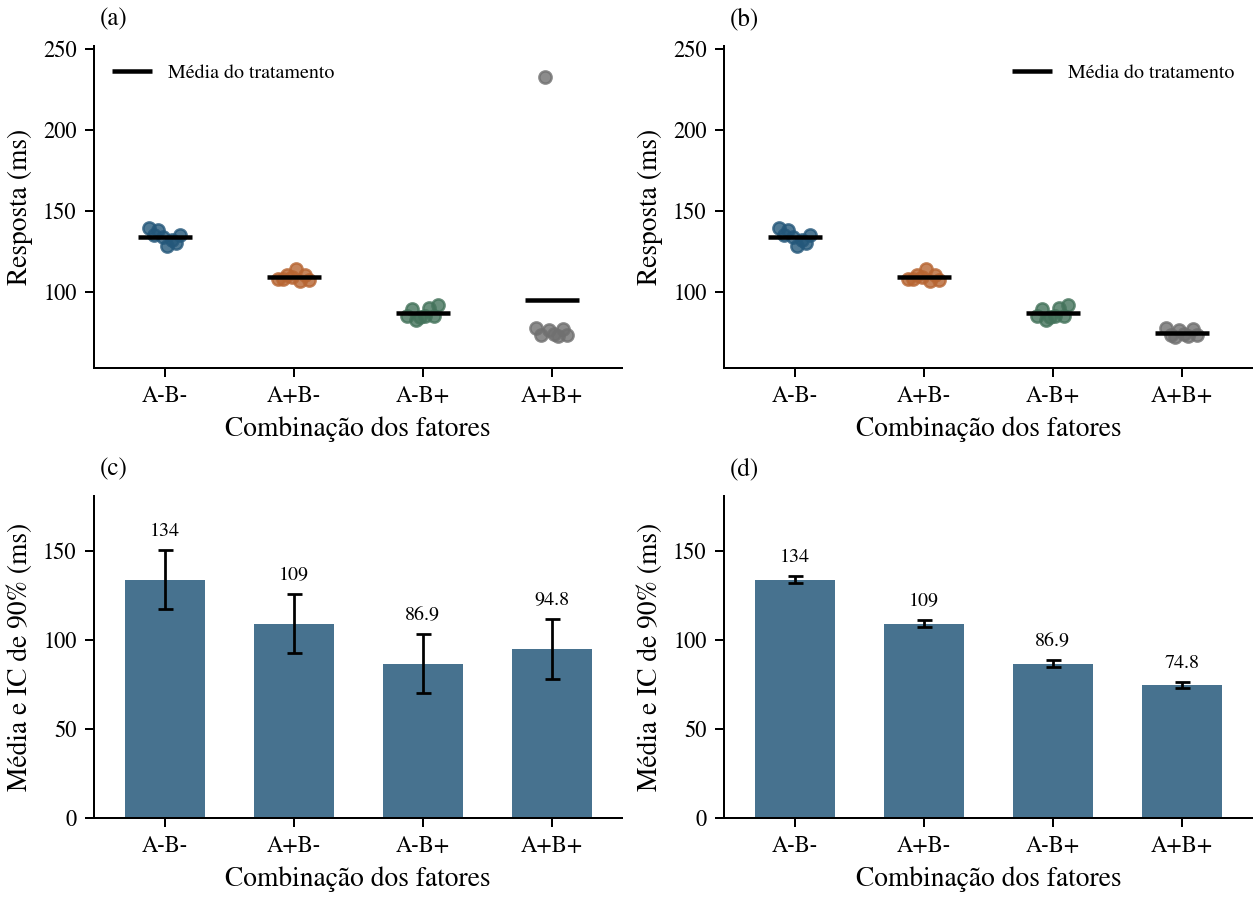

In [4]:
tabela_combinacoes = graficos_combinacoes_pareadas(
    [res_transcrita, res_conferida], ["Transcrição incorreta", "Registro conferido"],
    ["Workers", "Cache"], [["2 workers", "8 workers"], ["Desligado", "Ligado"]], "outlier_combinacoes",
    compartilhar_y=True)


In [5]:
comparacao_outlier = comparar_efeitos(
    [res_transcrita, res_conferida],
    ["Transcrição incorreta", "Registro conferido"],
    ["ms", "ms"], "outlier")


Para cada termo, o teste bilateral compara $H_0\quad q_j=0$ com $H_1\quad q_j\ne0$. A decisão usa o valor p e o alfa definido antes da análise. Os ICs e os testes clássicos dependem das condições do modelo.

,Análise,Termo,Escala,Estimativa q,IC inferior,IC superior,Valor p,Rejeita H0
0,Transcrição incorreta,qA,ms,-4.2008,-12.606,4.2043,0.4024,False
1,Transcrição incorreta,qB,ms,-15.437,-23.842,-7.0314,0.004121,True
2,Transcrição incorreta,qAB,ms,8.1812,-0.22386,16.586,0.1089,False
3,Registro conferido,qA,ms,-9.2008,-10.072,-8.3296,6.627e-17,True
4,Registro conferido,qB,ms,-20.437,-21.308,-19.565,3.189e-26,True
5,Registro conferido,qAB,ms,3.1812,2.31,4.0524,1.037e-06,True


**Transcrição incorreta para $q_{A}$**. Não é significativo porque o valor p de 0.4024 é maior ou igual a alfa igual a 0.1. Não rejeitamos a hipótese de coeficiente nulo. Isso não demonstra ausência de efeito.

**Transcrição incorreta para $q_{B}$**. É significativo porque o valor p de 0.004121 é menor que alfa igual a 0.1. Rejeitamos a hipótese de coeficiente nulo sob as condições do modelo.

**Transcrição incorreta para $q_{AB}$**. Não é significativo porque o valor p de 0.1089 é maior ou igual a alfa igual a 0.1. Não rejeitamos a hipótese de coeficiente nulo. Isso não demonstra ausência de efeito.

**Registro conferido para $q_{A}$**. É significativo porque o valor p de 6.627e-17 é menor que alfa igual a 0.1. Rejeitamos a hipótese de coeficiente nulo sob as condições do modelo.

**Registro conferido para $q_{B}$**. É significativo porque o valor p de 3.189e-26 é menor que alfa igual a 0.1. Rejeitamos a hipótese de coeficiente nulo sob as condições do modelo.

**Registro conferido para $q_{AB}$**. É significativo porque o valor p de 1.037e-06 é menor que alfa igual a 0.1. Rejeitamos a hipótese de coeficiente nulo sob as condições do modelo.

,Análise,A (%),B (%),AB (%),Erro (%)
0,Transcrição incorreta,1.7534,23.677,6.6506,67.919
1,Registro conferido,16.287,80.353,1.947,1.4129


### Efeitos antes e depois da conferência

Os ICs são individuais. As barras da versão incorreta mostram o resultado mecânico da conta, sem tornar válidas suas premissas. A resposta extrema desloca uma média de combinação e aumenta a estimativa da variação entre sessões.

A alocação da variação também muda. A parcela de erro e os contrastes são calculados do mesmo conjunto de respostas. Por isso, um erro de registro pode alterar tanto a magnitude aparente dos fatores quanto sua significância.


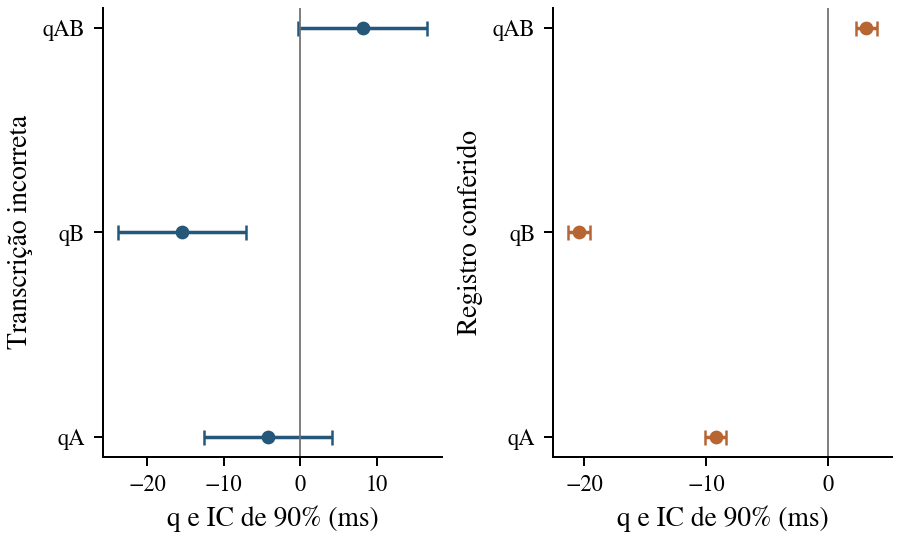

$$\widehat{y}=101.3 - 9.201x_{A} - 20.44x_{B} + 3.181x_{A}x_{B}.$$

In [6]:
graficos_comparacao(
    [res_transcrita, res_conferida],
    ["Transcrição incorreta", "Registro conferido"],
    "outlier_comparacao")
modelo_escrito(res_conferida, resposta="y")


A tabela da transcrição incorreta mostra a consequência numérica do registro conhecido como errado. Seus valores-p são referenciais e não sustentam uma conclusão sobre o funcionamento da API. A tabela do registro conferido usa as mesmas sessões com a transcrição corrigida. Sua leitura inferencial depende das condições do modelo e do protocolo dessas sessões.


In [7]:
mostrar_anovas_cenarios([
    {'resultado': res_transcrita, 'rotulo': 'Transcrição incorreta', 'escala': 'ms',
     'inferir': False, 'nota': 'O erro de registro foi identificado no cenário.'},
    {'resultado': res_conferida, 'rotulo': 'Registro conferido', 'escala': 'ms',
     'inferir': True, 'nota': 'A interpretação dos testes pressupõe as condições do modelo.'},
], 'outlier')


### ANOVA de Transcrição incorreta

Escala da resposta em ms. O erro de registro foi identificado no cenário.

,Fonte,SQ / SS,gl,QM / MS,F,Valor-p de referência
0,A,564.7,1,564.7,0.72287,0.4024
1,B,7625.2,1,7625.2,9.7609,0.004121
2,AB,2141.8,1,2141.8,2.7418,0.1089
3,Erro,21873,28,781.19,NaN,
4,Total,32205,31,NaN,NaN,


,F global,gl numerador,gl denominador,Valor-p de referência
0,4.4085,3,28,0.01164


A leitura é descritiva. A condição identificada neste cenário impede usar estes valores-p como evidência inferencial válida.

### ANOVA de Registro conferido

Escala da resposta em ms. A interpretação dos testes pressupõe as condições do modelo.

,Fonte,SQ / SS,gl,QM / MS,F,Valor-p
0,A,2709,1,2709,322.76,6.627e-17
1,B,13365,1,13365,1592.4,3.189e-26
2,AB,323.84,1,323.84,38.585,1.037e-06
3,Erro,235,28,8.393,NaN,
4,Total,16633,31,NaN,NaN,


,F global,gl numerador,gl denominador,Valor-p
0,651.24,3,28,5.44e-26


**Teste F global de Registro conferido**

É significativo porque o valor-p 5.44e-26 é menor ou igual a 0.10. Rejeitamos a hipótese de coeficientes explicativos todos nulos, sob as condições do modelo.

Se o valor alto constasse também no registro bruto e representasse uma pausa real do sistema, a correção não seria justificável. Nesse caso, a observação pertence à operação medida. O objetivo e o mecanismo precisariam ser investigados antes de decidir como descrever essa resposta. Um valor p ou um gráfico não substitui essa informação.


## Um erro no protocolo de coleta

Agora o objetivo e os fatores permanecem os mesmos. A equipe executa todas as sessões de uma combinação antes de passar para a próxima. Durante a campanha, a latência sofre uma deriva crescente. O momento de execução fica associado aos níveis dos fatores.

Essa falha não pode ser corrigida apenas embaralhando as linhas do arquivo depois da coleta. O contraste entre combinações já contém parte da mudança temporal. A análise pode produzir ICs e valores p, mas eles não separam os dois mecanismos.

Na nova campanha, o estado é estabilizado, o aquecimento é padronizado e a ordem é sorteada antes das sessões. As novas respostas são geradas separadamente. Elas não são uma permutação das respostas anteriores.


In [8]:
rng_coleta = np.random.default_rng(70502)
r_coleta = 8
N_coleta = 4 * r_coleta
ordem_agrupada = np.arange(1, N_coleta + 1).reshape(4, r_coleta)
deriva_ms = 2.0 * (ordem_agrupada - (N_coleta + 1) / 2)
response_deriva = media_geradora[:, None] + deriva_ms + rng_coleta.normal(
    0, 3.0, size=(4, r_coleta))

ordem_nova = rng_coleta.permutation(np.arange(1, N_coleta + 1)).reshape(4, r_coleta)
response_nova = media_geradora[:, None] + rng_coleta.normal(
    0, 3.0, size=(4, r_coleta))
res_deriva = ajustar(response_deriva)
res_nova = ajustar(response_nova)
res_deriva["unidade"] = "ms"
res_nova["unidade"] = "ms"


### Respostas nas duas campanhas

A escala comum permite comparar as médias e a dispersão das campanhas. A proximidade das médias na coleta com deriva não demonstra que os fatores tenham pouco efeito. O momento da execução participa dessas diferenças. A nova campanha contém outras sessões, com protocolo estabilizado e ordem sorteada antes da coleta.


Painéis do gráfico. (a) Pontos de Coleta com deriva. (b) Pontos de Nova coleta. (c) Média e IC de Coleta com deriva. (d) Média e IC de Nova coleta.

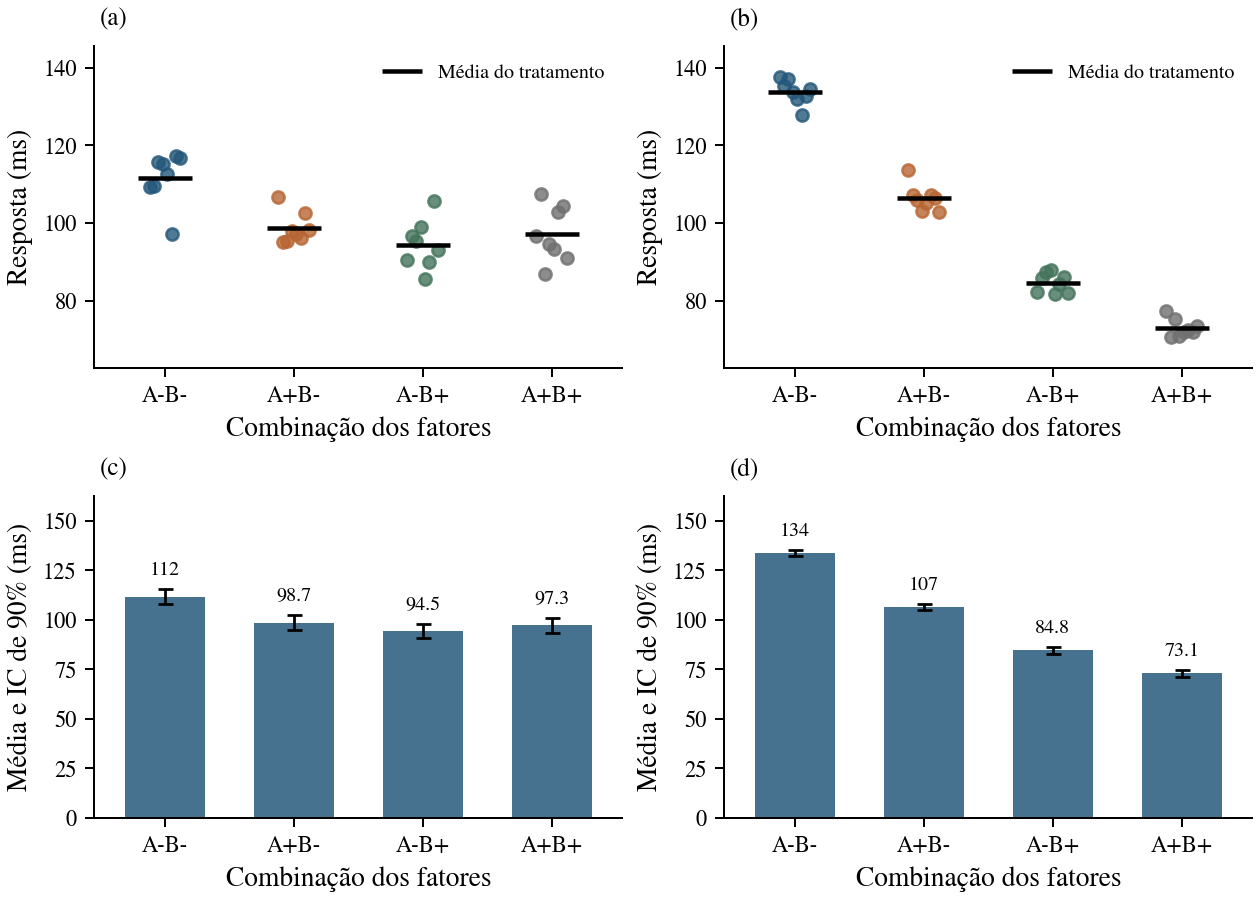

In [9]:
tabela_combinacoes = graficos_combinacoes_pareadas(
    [res_deriva, res_nova], ["Coleta com deriva", "Nova coleta"],
    ["Workers", "Cache"], [["2 workers", "8 workers"], ["Desligado", "Ligado"]], "coleta_combinacoes",
    compartilhar_y=True)


Para cada termo, o teste bilateral compara $H_0\quad q_j=0$ com $H_1\quad q_j\ne0$. A decisão usa o valor p e o alfa definido antes da análise. Os ICs e os testes clássicos dependem das condições do modelo.

,Análise,Termo,Escala,Estimativa q,IC inferior,IC superior,Valor p,Rejeita H0
0,Coleta com deriva,qA,ms,-2.5773,-4.412,-0.74261,0.02384,True
1,Coleta com deriva,qB,ms,-4.6708,-6.5055,-2.8361,0.0001721,True
2,Coleta com deriva,qAB,ms,3.944,2.1093,5.7787,0.001046,True
3,Nova coleta,qA,ms,-9.7288,-10.582,-8.8755,9.043e-18,True
4,Nova coleta,qB,ms,-20.618,-21.471,-19.764,1.408e-26,True
5,Nova coleta,qAB,ms,3.9141,3.0609,4.7673,1.682e-08,True


**Coleta com deriva para $q_{A}$**. É significativo porque o valor p de 0.02384 é menor que alfa igual a 0.1. Rejeitamos a hipótese de coeficiente nulo sob as condições do modelo.

**Coleta com deriva para $q_{B}$**. É significativo porque o valor p de 0.0001721 é menor que alfa igual a 0.1. Rejeitamos a hipótese de coeficiente nulo sob as condições do modelo.

**Coleta com deriva para $q_{AB}$**. É significativo porque o valor p de 0.001046 é menor que alfa igual a 0.1. Rejeitamos a hipótese de coeficiente nulo sob as condições do modelo.

**Nova coleta para $q_{A}$**. É significativo porque o valor p de 9.043e-18 é menor que alfa igual a 0.1. Rejeitamos a hipótese de coeficiente nulo sob as condições do modelo.

**Nova coleta para $q_{B}$**. É significativo porque o valor p de 1.408e-26 é menor que alfa igual a 0.1. Rejeitamos a hipótese de coeficiente nulo sob as condições do modelo.

**Nova coleta para $q_{AB}$**. É significativo porque o valor p de 1.682e-08 é menor que alfa igual a 0.1. Rejeitamos a hipótese de coeficiente nulo sob as condições do modelo.

,Análise,A (%),B (%),AB (%),Erro (%)
0,Coleta com deriva,8.6736,28.487,20.311,42.528
1,Nova coleta,17.46,78.415,2.8261,1.2994


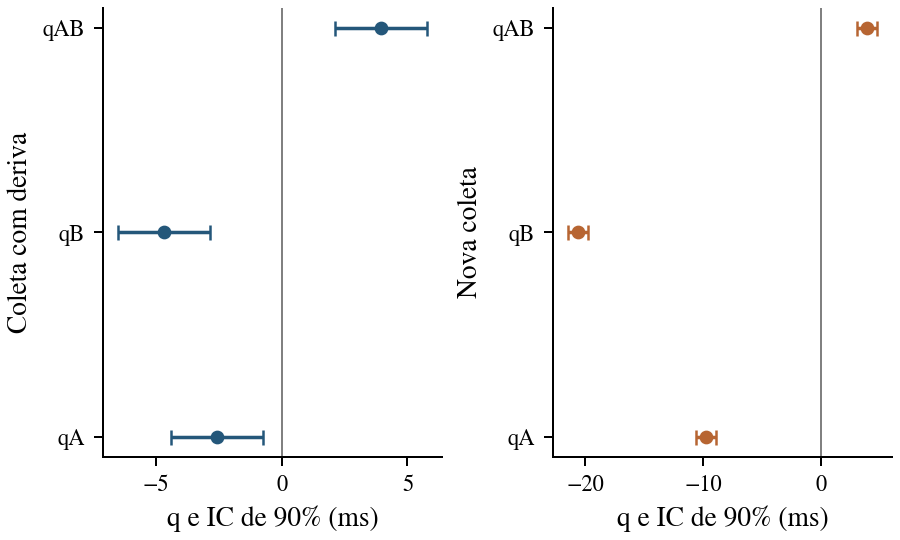

In [10]:
comparacao_coleta = comparar_efeitos(
    [res_deriva, res_nova],
    ["Coleta com deriva", "Nova coleta"],
    ["ms", "ms"], "coleta")

graficos_comparacao(
    [res_deriva, res_nova],
    ["Coleta com deriva", "Nova coleta"],
    "coleta_comparacao")


Na coleta com deriva, os contrastes entre configurações também incorporam a mudança temporal. A ANOVA dessa versão é uma descrição das contas e não separa o efeito dos fatores do efeito da ordem. A nova coleta tem sua própria ANOVA. A leitura de seus testes depende do protocolo estabilizado e das condições do modelo.


In [11]:
mostrar_anovas_cenarios([
    {'resultado': res_deriva, 'rotulo': 'Coleta com deriva', 'escala': 'ms',
     'inferir': False, 'nota': 'A ordem de execução se confunde com os fatores.'},
    {'resultado': res_nova, 'rotulo': 'Nova coleta', 'escala': 'ms',
     'inferir': True, 'nota': 'A interpretação dos testes pressupõe o protocolo estabilizado e as condições do modelo.'},
], 'coleta')


### ANOVA de Coleta com deriva

Escala da resposta em ms. A ordem de execução se confunde com os fatores.

,Fonte,SQ / SS,gl,QM / MS,F,Valor-p de referência
0,A,212.56,1,212.56,5.7106,0.02384
1,B,698.11,1,698.11,18.755,0.0001721
2,AB,497.76,1,497.76,13.373,0.001046
3,Erro,1042.2,28,37.222,NaN,
4,Total,2450.6,31,NaN,NaN,


,F global,gl numerador,gl denominador,Valor-p de referência
0,12.613,3,28,2.13e-05


A leitura é descritiva. A condição identificada neste cenário impede usar estes valores-p como evidência inferencial válida.

### ANOVA de Nova coleta

Escala da resposta em ms. A interpretação dos testes pressupõe o protocolo estabilizado e as condições do modelo.

,Fonte,SQ / SS,gl,QM / MS,F,Valor-p
0,A,3028.8,1,3028.8,376.24,9.043e-18
1,B,13603,1,13603,1689.8,1.408e-26
2,AB,490.24,1,490.24,60.899,1.682e-08
3,Erro,225.4,28,8.0502,NaN,
4,Total,17347,31,NaN,NaN,


,F global,gl numerador,gl denominador,Valor-p
0,708.97,3,28,1.684e-26


**Teste F global de Nova coleta**

É significativo porque o valor-p 1.684e-26 é menor ou igual a 0.10. Rejeitamos a hipótese de coeficientes explicativos todos nulos, sob as condições do modelo.

### Resíduos na sequência realmente executada

No modelo completo, cada resíduo é a resposta menos a média de sua combinação. Parte da deriva pode ser absorvida pelas quatro médias. Mesmo assim, a sequência residual pode revelar a mudança dentro de cada conjunto de sessões.

A estatística de Durbin e Watson usa

$$DW=\frac{\sum_{t=2}^{N}(e_t-e_{t-1})^2}{\sum_{t=1}^{N}e_t^2}.$$

Nesta comparação da coleta, apresentamos somente a estatística DW como descrição da sequência. Valores próximos de 2 são compatíveis com ausência de correlação de primeira ordem, mas não comprovam independência. Não usamos um corte universal para aprovar a coleta. A evidência principal continua sendo a forma como as sessões foram realizadas.


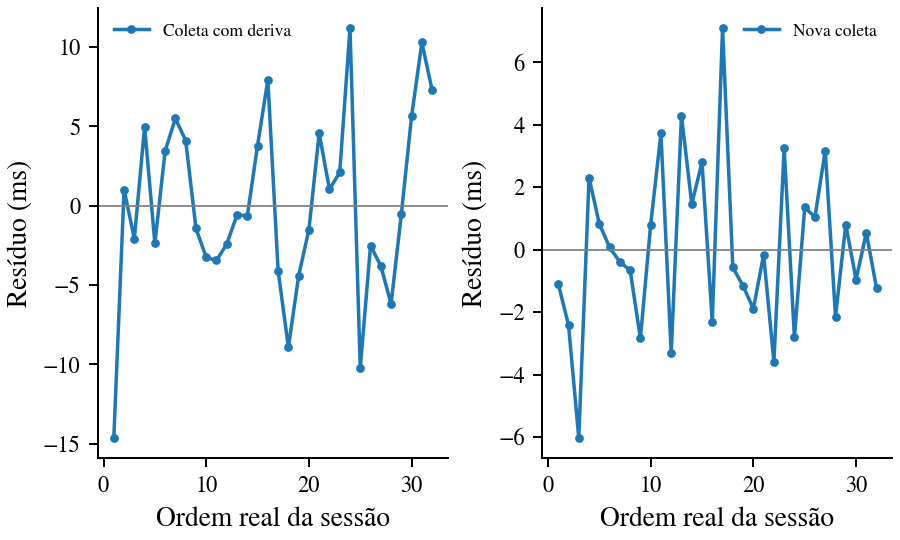

,Campanha,Durbin e Watson
0,Coleta com deriva,1.3729
1,Nova coleta,2.5355


In [12]:
fig, eixos = plt.subplots(1, 2, figsize=(5, 3), layout="constrained")
linhas_dw = []
for ax, response, ordem, nome in zip(
    eixos,
    [response_deriva, response_nova],
    [ordem_agrupada, ordem_nova],
    ["Coleta com deriva", "Nova coleta"],
):
    residuos = response - response.mean(axis=1, keepdims=True)
    indice_tempo = np.argsort(ordem.ravel())
    e_t = residuos.ravel()[indice_tempo]
    ax.plot(np.arange(1, e_t.size + 1), e_t, "o-", markersize=2.5, label=nome)
    ax.axhline(0, color="0.5", linewidth=0.7)
    ax.set_xlabel("Ordem real da sessão")
    ax.set_ylabel("Resíduo (ms)")
    ax.legend(frameon=False, fontsize=7)
    linhas_dw.append({"Campanha": nome,
                       "Durbin e Watson": np.sum(np.diff(e_t) ** 2) / np.sum(e_t ** 2)})
salvar_figura(fig, "coleta_residuos_ordem")
display(pd.DataFrame(linhas_dw))


A nova coleta deve ser julgada pelo protocolo registrado, pela dispersão e pela ordem temporal. A ausência de tendência visível não demonstra independência. Corrigir a transcrição de um número e refazer uma campanha com falha de execução são ações diferentes porque recuperam informações diferentes.


## Uma resposta positiva com variação proporcional

O objetivo é descrever o tempo de uma transferência de dados. A representa 1.000 ou 2.000 itens. B representa itens de 16 ou 64 KiB. Cada réplica é uma nova sessão, com o mesmo enlace e o mesmo protocolo de preparação. Esperamos que mais itens e itens maiores aumentem o tempo. Como o volume depende das duas quantidades, seus efeitos podem parecer multiplicativos na escala original.

Os dados são gerados com erros normais aditivos no log. Isso produz respostas positivas com variação relativa. A geração é conhecida neste exemplo. Em uma medição real, a justificativa da escala dependeria também do mecanismo e dos resíduos.

Com $y_{ref}=1$ ms, o modelo é escrito explicitamente como

$$\log(y/y_{ref})=q_0+q_Ax_A+q_Bx_B+q_{AB}x_Ax_B+e_{log}.$$

Definimos $z=\log(y/y_{ref})$ para ajustar esse mesmo fatorial na escala transformada. A comparação com a análise direta de $y$ preserva as sessões, os fatores e as replicações. As unidades dos coeficientes mudam.


In [13]:
rng_log = np.random.default_rng(70503)
r_log = 12
q_log_gerador = np.array([4.6, 0.35, 0.65, 0.0])
ordem_log = rng_log.permutation(np.arange(1, 4 * r_log + 1)).reshape(4, r_log)
indice_ordem_log = np.argsort(ordem_log.ravel())
z_gerado = (configuracoes @ q_log_gerador)[:, None] + rng_log.normal(
    0, 0.18, size=(4, r_log))
y_ref_ms = 1.0
response_multiplicativa = y_ref_ms * np.exp(z_gerado)
z = np.log(response_multiplicativa / y_ref_ms)

res_original = ajustar(response_multiplicativa)
res_log = ajustar(z)
res_original["unidade"] = "ms"
res_log["unidade"] = "adimensional"


### Respostas nas escalas original e log

Os dois lados representam as mesmas sessões em escalas diferentes. Na escala original, os valores estão em ms. Na escala log, os pontos, as médias e os ICs são adimensionais e descrevem $\log(y/y_{ref})$. As alturas e larguras não devem ser comparadas como se tivessem a mesma unidade. A média do log não é a média aritmética da resposta original.


Painéis do gráfico. (a) Pontos de Escala original. (b) Pontos de Escala log. (c) Média e IC de Escala original. (d) Média e IC de Escala log.

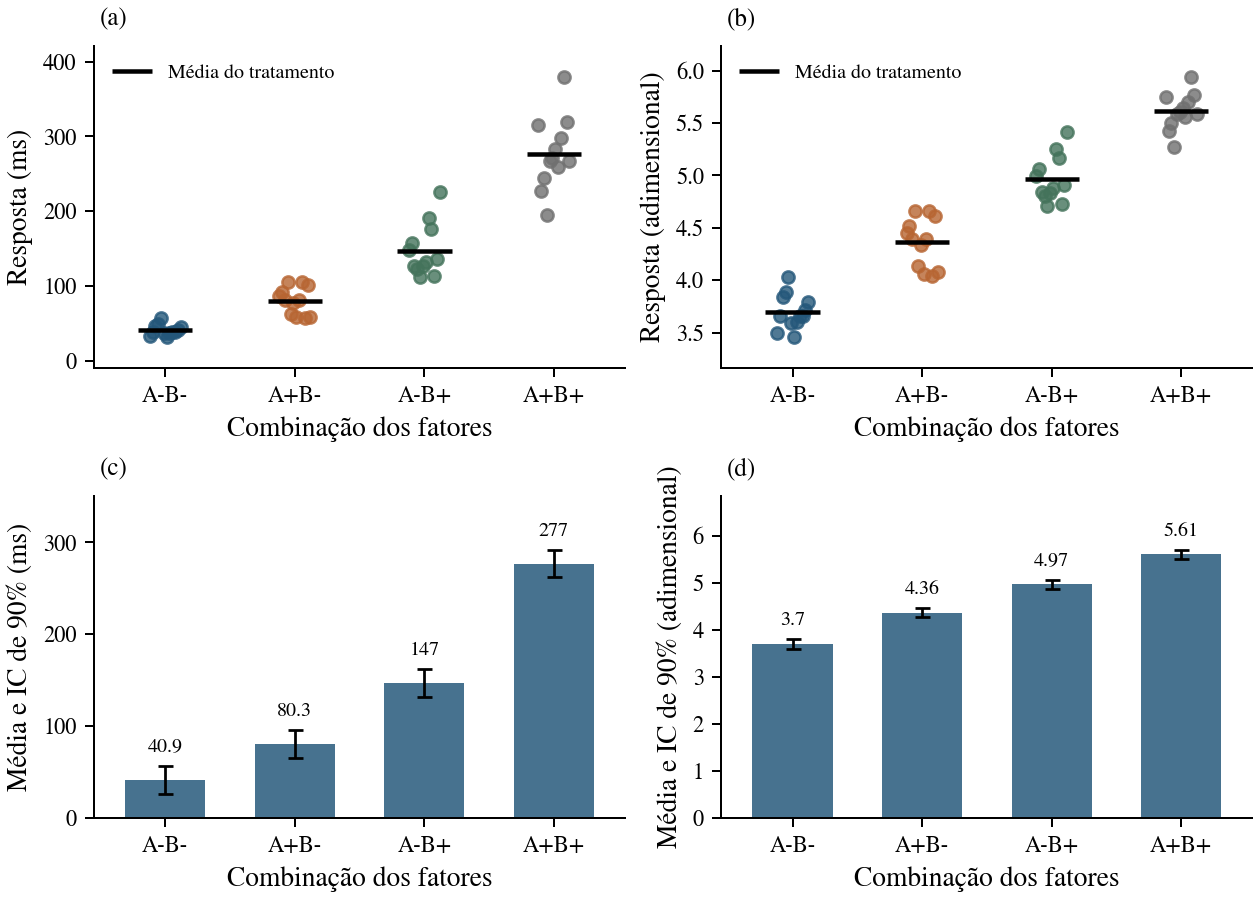

In [14]:
tabela_combinacoes = graficos_combinacoes_pareadas(
    [res_original, res_log], ["Escala original", "Escala log"],
    ["Quantidade de itens", "Tamanho dos itens"], [["1.000", "2.000"], ["16 KiB", "64 KiB"]], "log_combinacoes",
    compartilhar_y=False)


In [15]:
comparacao_log = comparar_efeitos(
    [res_original, res_log],
    ["Escala original", "Escala log"],
    ["ms", "adimensional"], "log")
modelo_escrito(res_original, resposta="y")
modelo_escrito(res_log, resposta="z")


Para cada termo, o teste bilateral compara $H_0\quad q_j=0$ com $H_1\quad q_j\ne0$. A decisão usa o valor p e o alfa definido antes da análise. Os ICs e os testes clássicos dependem das condições do modelo.

,Análise,Termo,Escala,Estimativa q,IC inferior,IC superior,Valor p,Rejeita H0
0,Escala original,qA,ms,42.353,34.801,49.905,4.046e-12,True
1,Escala original,qB,ms,75.683,68.131,83.236,8.476e-21,True
2,Escala original,qAB,ms,22.678,15.126,30.23,8.296e-06,True
3,Escala log,qA,adimensional,0.32634,0.27789,0.37479,1.284e-14,True
4,Escala log,qB,adimensional,0.62917,0.58072,0.67762,3.15e-25,True
5,Escala log,qAB,adimensional,-0.0045133,-0.052963,0.043937,0.8763,False


**Escala original para $q_{A}$**. É significativo porque o valor p de 4.046e-12 é menor que alfa igual a 0.1. Rejeitamos a hipótese de coeficiente nulo sob as condições do modelo.

**Escala original para $q_{B}$**. É significativo porque o valor p de 8.476e-21 é menor que alfa igual a 0.1. Rejeitamos a hipótese de coeficiente nulo sob as condições do modelo.

**Escala original para $q_{AB}$**. É significativo porque o valor p de 8.296e-06 é menor que alfa igual a 0.1. Rejeitamos a hipótese de coeficiente nulo sob as condições do modelo.

**Escala log para $q_{A}$**. É significativo porque o valor p de 1.284e-14 é menor que alfa igual a 0.1. Rejeitamos a hipótese de coeficiente nulo sob as condições do modelo.

**Escala log para $q_{B}$**. É significativo porque o valor p de 3.15e-25 é menor que alfa igual a 0.1. Rejeitamos a hipótese de coeficiente nulo sob as condições do modelo.

**Escala log para $q_{AB}$**. Não é significativo porque o valor p de 0.8763 é maior ou igual a alfa igual a 0.1. Não rejeitamos a hipótese de coeficiente nulo. Isso não demonstra ausência de efeito.

,Análise,A (%),B (%),AB (%),Erro (%)
0,Escala original,20.098,64.179,5.7624,9.9599
1,Escala log,19.76,73.449,0.0037795,6.7881


$$\widehat{y}=136.3 + 42.35x_{A} + 75.68x_{B} + 22.68x_{A}x_{B}.$$

$$\widehat{z}=4.66 + 0.3263x_{A} + 0.6292x_{B} - 0.004513x_{A}x_{B}.$$

Na escala original, a variação absoluta cresce com a média e contraria o MSE comum usado na referência clássica. Nessa tabela, os valores-p são referenciais. Na escala log, a leitura inferencial depende da adequação dos erros nessa escala. As SQ e os QM da resposta original têm unidade ms². Na escala log, são adimensionais. Seus valores absolutos não devem ser comparados como se tivessem a mesma unidade. F e valor-p respondem às hipóteses de cada escala e não escolhem, sozinhos, a transformação.


In [16]:
mostrar_anovas_cenarios([
    {'resultado': res_original, 'rotulo': 'Escala original', 'escala': 'ms',
     'inferir': False, 'nota': 'A variância comum é inadequada para a resposta original deste cenário.'},
    {'resultado': res_log, 'rotulo': 'Escala log', 'escala': 'log da razão entre resposta e referência',
     'inferir': True, 'nota': 'A interpretação dos testes pressupõe adequação dos erros na escala log.'},
], 'log')


### ANOVA de Escala original

Escala da resposta em ms. A variância comum é inadequada para a resposta original deste cenário.

,Fonte,SQ / SS,gl,QM / MS,F,Valor-p de referência
0,A,86101,1,86101,88.788,4.046e-12
1,B,2.7494e+05,1,2.7494e+05,283.53,8.476e-21
2,AB,24686,1,24686,25.457,8.296e-06
3,Erro,42668,44,969.73,NaN,
4,Total,4.284e+05,47,NaN,NaN,


,F global,gl numerador,gl denominador,Valor-p de referência
0,132.59,3,44,4.686e-22


A leitura é descritiva. A condição identificada neste cenário impede usar estes valores-p como evidência inferencial válida.

### ANOVA de Escala log

Escala da resposta em log da razão entre resposta e referência. A interpretação dos testes pressupõe adequação dos erros na escala log.

,Fonte,SQ / SS,gl,QM / MS,F,Valor-p
0,A,5.1118,1,5.1118,128.08,1.284e-14
1,B,19.001,1,19.001,476.09,3.15e-25
2,AB,0.00097777,1,0.00097777,0.024499,0.8763
3,Erro,1.7561,44,0.039911,NaN,
4,Total,25.87,47,NaN,NaN,


,F global,gl numerador,gl denominador,Valor-p
0,201.4,3,44,1.035e-25


**Teste F global de Escala log**

É significativo porque o valor-p 1.035e-25 é menor ou igual a 0.10. Rejeitamos a hipótese de coeficientes explicativos todos nulos, sob as condições do modelo.

### Coeficientes e significância nas duas escalas

Cada par de hipóteses se refere à escala de seu modelo. Os coeficientes em ms descrevem diferenças aditivas de tempo. Os coeficientes no log são adimensionais e descrevem mudanças multiplicativas na resposta original.

Uma interação na escala original pode diminuir no log porque a soma no log representa um produto na escala original. Isso não é contradição entre os testes. A questão científica e a adequação dos erros precisam orientar a escolha. Um valor p favorável, sozinho, não escolhe a transformação.

Cada painel tem sua própria escala horizontal. Os comprimentos das barras em ms e no log não devem ser comparados como se tivessem a mesma unidade.


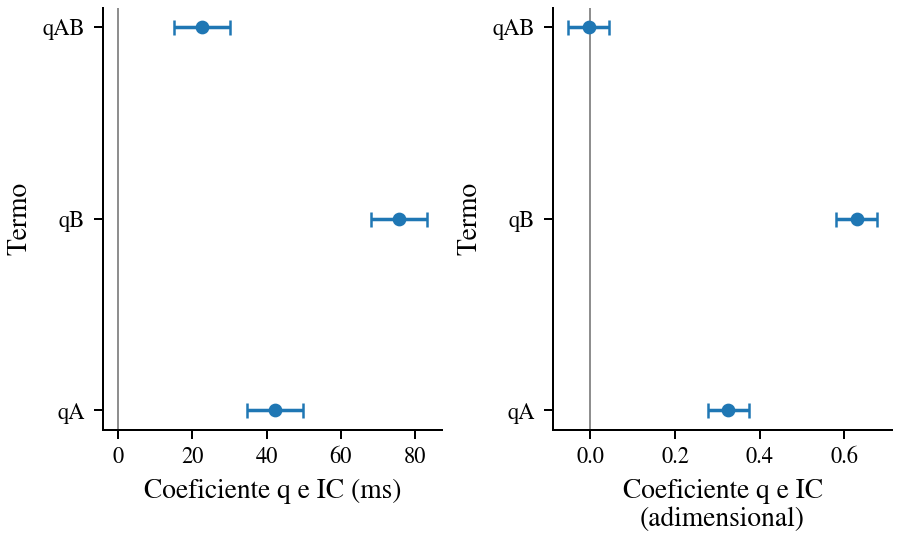

In [17]:
fig, eixos = plt.subplots(1, 2, figsize=(5, 3), layout="constrained")
for ax, res, unidade in zip(
    eixos,
    [res_original, res_log],
    ["Coeficiente q e IC (ms)", "Coeficiente q e IC\n(adimensional)"],
):
    margem = stats.t.ppf(1 - ALPHA / 2, res["nu"]) * res["sq"]
    ax.errorbar(res["q"][1:], np.arange(3), xerr=margem, fmt="o", capsize=3)
    ax.axvline(0, color="0.5", linewidth=0.7)
    ax.set_yticks(np.arange(3), ["qA", "qB", "qAB"])
    ax.set_xlabel(unidade)
    ax.set_ylabel("Termo")
salvar_figura(fig, "log_efeitos_duas_escalas")


### Condições do modelo

**Forma da resposta média**

O modelo precisa representar as médias nas condições estudadas. O completo reproduz as médias das combinações fatoriais. Isso deixa zero grau de liberdade para testar falta de ajuste entre esses pontos e não demonstra ausência de curvatura entre os níveis. O gráfico de resíduos contra os valores ajustados ajuda a investigar padrões, mas não certifica a forma do modelo.

**Homocedasticidade dos erros**

A variância deve permanecer aproximadamente constante. O teste de Levene centrado na mediana, conhecido como Brown e Forsythe, usa $H_0$ de variâncias iguais entre as combinações. Em $H_A$, pelo menos uma difere. Sua referência F é aproximada. O gráfico por combinação complementa o teste.

**Independência dos erros**

Os erros de sessões distintas não devem apresentar dependência sistemática. A ordem realmente executada é preservada no gráfico temporal. Durbin e Watson compara diferenças entre resíduos sucessivos com sua soma de quadrados. Valores próximos de 2 sugerem pouca associação de primeira ordem, valores menores sugerem associação positiva e maiores sugerem associação negativa. A referência usada para o valor-p simula erros normais independentes com variância comum sob o mesmo desenho. A alternativa procura dependência serial. O protocolo e o gráfico continuam necessários.

**Normalidade dos erros**

O Q-Q compara os quantis dos resíduos com os da normal. Nos testes de Shapiro e Wilk e de Kolmogorov e Smirnov, $H_0$ afirma normalidade dos erros e $H_A$ afirma desvio dessa forma. O segundo usa média e variância estimadas, como na formulação de Lilliefors. Como os resíduos compartilham parâmetros ajustados, os valores-p dos dois testes são calibrados com erros normais e o mesmo ajuste fatorial. Essa referência depende das demais condições do modelo. Durbin e Watson avalia dependência temporal, não normalidade.

Um teste significativo apresenta evidência contra sua hipótese nula. Um resultado não significativo indica evidência insuficiente para rejeitá-la. Nenhum valor-p demonstra que uma condição é verdadeira. A decisão considera os gráficos, a unidade experimental e o protocolo.


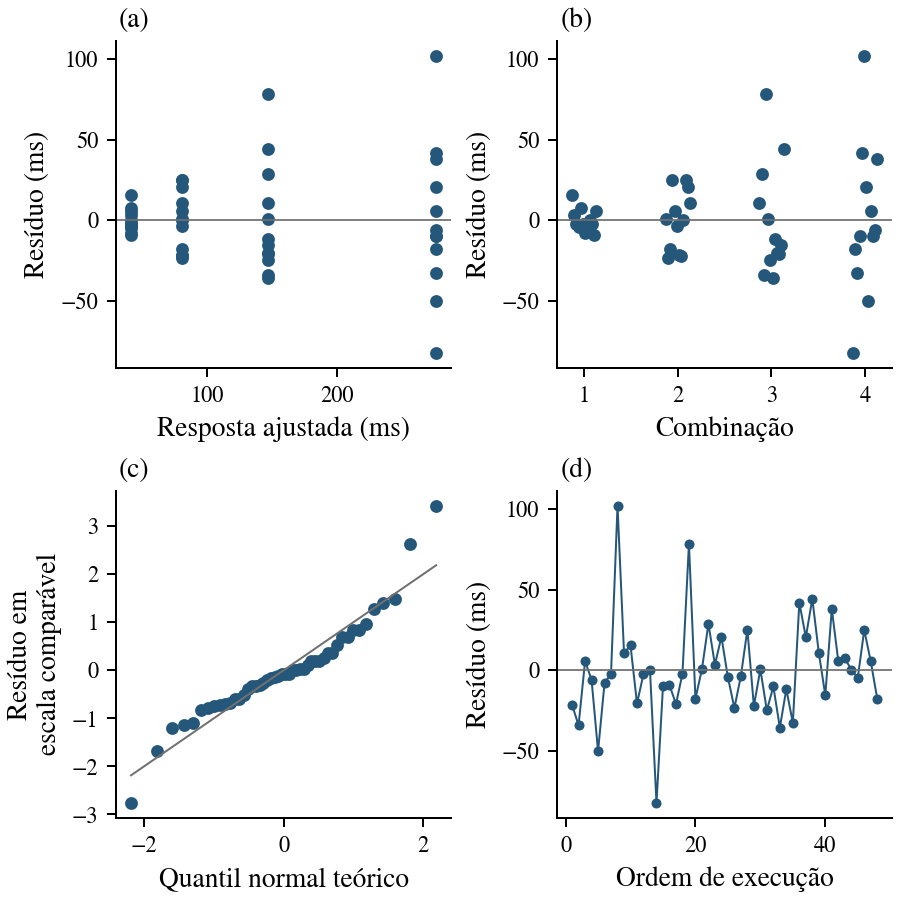

,Diagnóstico,Estatística,Valor-p,Referência
0,Brown e Forsythe,3.8586,0.01553,F aproximada
1,Shapiro e Wilk,0.92892,0.0082,Normal no mesmo desenho
2,Kolmogorov e Smirnov,0.13252,0.0354,Normal no mesmo desenho
3,Durbin e Watson,1.8465,0.5732,Normal independente no mesmo desenho


**Homocedasticidade**

É significativo porque o valor-p 0.01553 é menor ou igual a 0.10. Há evidência contra a igualdade das variâncias.

**Shapiro e Wilk**

É significativo porque o valor-p 0.0082 é menor ou igual a 0.10. Há evidência contra a normalidade dos erros sob a referência adotada.

**Kolmogorov e Smirnov**

É significativo porque o valor-p 0.0354 é menor ou igual a 0.10. Há evidência contra a normalidade dos erros sob a referência adotada.

**Durbin e Watson**

Não é significativo porque o valor-p 0.5732 é maior que 0.10. Não há evidência suficiente de dependência serial nessa comparação. O protocolo continua necessário.

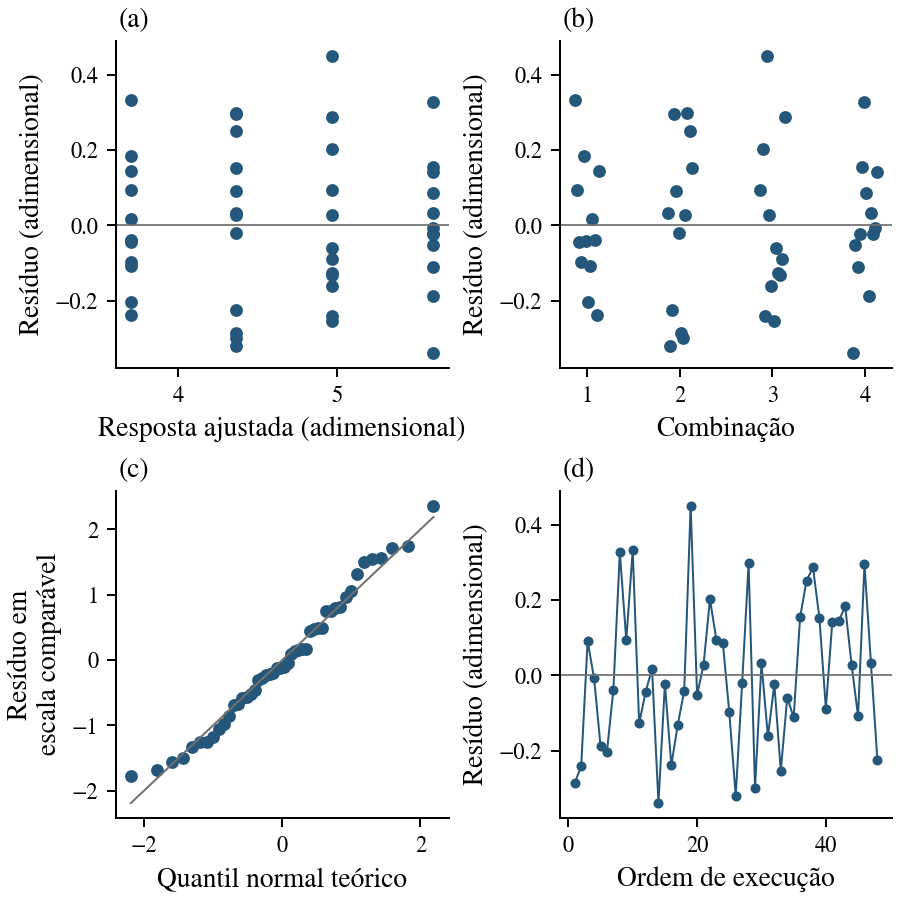

,Diagnóstico,Estatística,Valor-p,Referência
0,Brown e Forsythe,0.76064,0.5222,F aproximada
1,Shapiro e Wilk,0.97933,0.5496,Normal no mesmo desenho
2,Kolmogorov e Smirnov,0.077398,0.6678,Normal no mesmo desenho
3,Durbin e Watson,1.6736,0.2172,Normal independente no mesmo desenho


**Homocedasticidade**

Não é significativo porque o valor-p 0.5222 é maior que 0.10. Não há evidência suficiente contra a igualdade das variâncias.

**Shapiro e Wilk**

Não é significativo porque o valor-p 0.5496 é maior que 0.10. Não há evidência suficiente contra a normalidade sob a referência adotada.

**Kolmogorov e Smirnov**

Não é significativo porque o valor-p 0.6678 é maior que 0.10. Não há evidência suficiente contra a normalidade sob a referência adotada.

**Durbin e Watson**

Não é significativo porque o valor-p 0.2172 é maior que 0.10. Não há evidência suficiente de dependência serial nessa comparação. O protocolo continua necessário.

In [18]:
grid_residuos(res_original, indice_ordem_log, "log_diagnosticos_original")
testes_original = diagnosticos(res_original, indice_ordem_log, "log_testes_original")
grid_residuos(res_log, indice_ordem_log, "log_diagnosticos_transformado")
testes_log = diagnosticos(res_log, indice_ordem_log, "log_testes_transformado")


Na escala original, a variação absoluta pode crescer junto do tempo ajustado. No log, a amplitude passa a representar variação relativa. O Q-Q e os testes de normalidade complementam essa comparação.

O Shapiro e Wilk e o KS usam a referência dos resíduos ajustados descrita acima. Eles não demonstram independência nem corrigem variâncias diferentes. Se a dispersão contradiz a variância comum na escala original, a leitura da normalidade também fica condicionada a essa limitação. O gráfico sequencial e Durbin e Watson continuam dependendo da ordem efetiva das mesmas sessões.


## Referências

- Aula de Projeto e Análise de Experimentos. Material da disciplina.
- Raj Jain. *The Art of Computer Systems Performance Analysis*. Wiley, 1991. Capítulos 16 a 18. [Material do autor](https://www.cse.wustl.edu/~jain/books/perf_sli.htm) e [errata](https://www.cse.wustl.edu/~jain/books/ftp/errors_all.pdf).
- Douglas C. Montgomery. *Design and Analysis of Experiments*. Planejamento fatorial, análise de variância e adequação de modelos. [Sumário da editora](https://bcs.wiley.com/he-bcs/Books?action=contents&bcsId=11447&itemId=1119492440).
- NIST/SEMATECH. [Delineamentos fatoriais de dois níveis](https://www.itl.nist.gov/div898/handbook/pri/section3/pri3331.htm), [intervalos para a média](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm) e [Levene](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35a.htm).
- SciPy. [Shapiro e Wilk](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html). Statsmodels. [Lilliefors](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.lilliefors.html) e [Durbin e Watson](https://www.statsmodels.org/stable/generated/statsmodels.stats.stattools.durbin_watson.html). SciPy. [Calibração Monte Carlo com parâmetros estimados](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.goodness_of_fit.html). Referências de implementação dos diagnósticos.
